In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("ENGE707 environment is working!")

ENGE707 environment is working!


In [2]:
from pathlib import Path
import pandas as pd

# Locate the training labels
csv_files = list(Path(".").rglob("train_labels.csv"))

print("Training label files found:", csv_files)

Training label files found: [WindowsPath('train_labels.csv')]


In [3]:
# Load the training labels
train_df = pd.read_csv("train_labels.csv")

# Display the first five rows
print(train_df.head())

# Check the dataset dimensions
print("Dataset shape:", train_df.shape)

# Check the column names
print("Columns:", train_df.columns.tolist())

   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogFace
3         4   DogNose
4         5   DogNose
Dataset shape: (63660, 2)
Columns: ['image_id', 'class']


In [4]:
# Count images in each class
class_counts = train_df["class"].value_counts()

print("Number of images in each class:")
print(class_counts)

print("\nTotal training images:", len(train_df))

Number of images in each class:
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64

Total training images: 63660


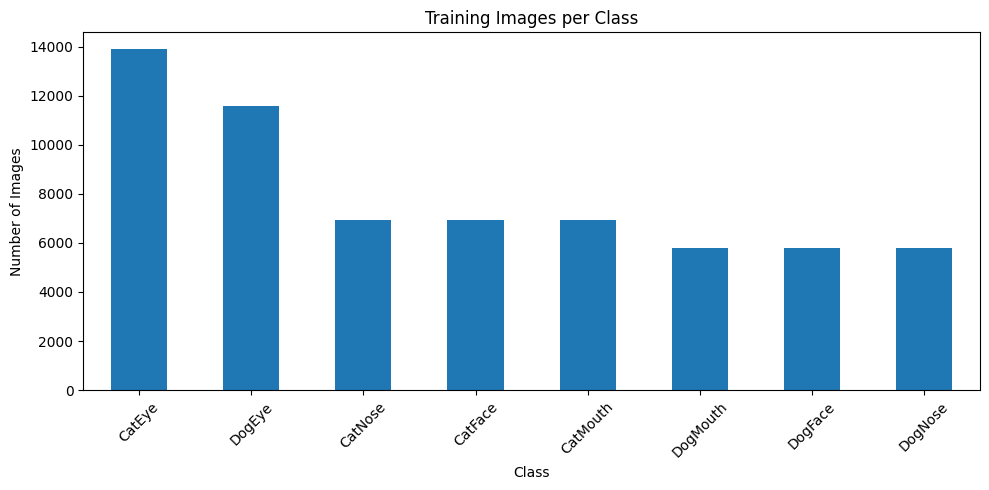

In [5]:
import matplotlib.pyplot as plt

class_counts = train_df["class"].value_counts()

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")

plt.title("Training Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
# Calculate percentage of each class
class_percentages = train_df["class"].value_counts(normalize=True) * 100

print("Class distribution (%):")
print(class_percentages.round(2))

Class distribution (%):
class
CatEye      21.81
DogEye      18.19
CatNose     10.90
CatFace     10.90
CatMouth    10.90
DogMouth     9.10
DogFace      9.10
DogNose      9.10
Name: proportion, dtype: float64


In [7]:
# Check for missing values
print("Missing values:")
print(train_df.isnull().sum())

# Check for duplicate image IDs
print("\nDuplicate image IDs:")
print(train_df["image_id"].duplicated().sum())

Missing values:
image_id    0
class       0
dtype: int64

Duplicate image IDs:
0


In [9]:
from PIL import Image
from pathlib import Path

# Find image files inside train and its subfolders
image_files = [
    p for p in Path("train").rglob("*")
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Images found:", len(image_files))

# Inspect the first 10 images
for image_path in image_files[:10]:
    with Image.open(image_path) as img:
        print(image_path.name, ":", img.size)

Images found: 63660
00001.jpg : (36, 36)
00002.jpg : (214, 157)
00003.jpg : (97, 97)
00004.jpg : (110, 110)
00005.jpg : (42, 42)
00006.jpg : (28, 28)
00007.jpg : (182, 135)
00008.jpg : (128, 128)
00009.jpg : (343, 376)
00010.jpg : (36, 36)


In [10]:
print("Training labels:", len(train_df))
print("Training image files:", len(image_files))

print("Difference:", len(image_files) - len(train_df))

Training labels: 63660
Training image files: 63660
Difference: 0


In [11]:
# Collect image IDs from the actual files
file_ids = {p.stem for p in image_files}

# Collect image IDs from the CSV
label_ids = set(
    train_df["image_id"].astype(str).str.zfill(5)
)

# Compare both sets
print("Images without labels:", len(file_ids - label_ids))
print("Labels without images:", len(label_ids - file_ids))

Images without labels: 0
Labels without images: 0


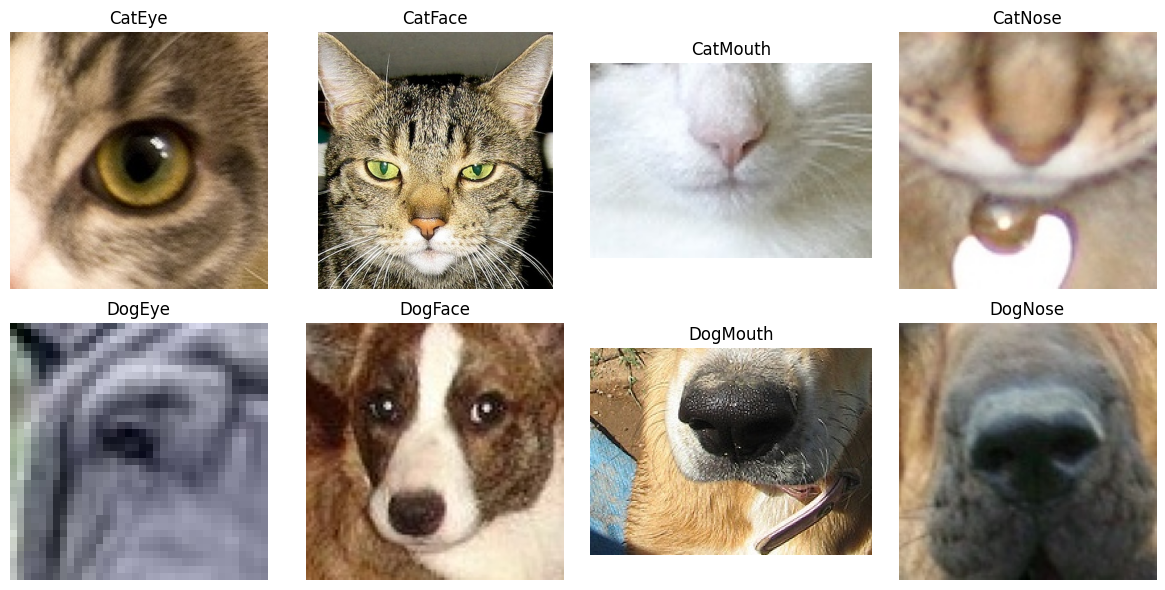

In [12]:
import matplotlib.pyplot as plt
from PIL import Image

# Create a lookup of image IDs and file paths
image_lookup = {p.stem: p for p in image_files}

# Display one image from each class
classes = sorted(train_df["class"].unique())

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, class_name in zip(axes.flat, classes):

    # Select one image belonging to this class
    sample = train_df[train_df["class"] == class_name].iloc[0]

    # Find the corresponding image
    image_id = str(sample["image_id"]).zfill(5)
    image_path = image_lookup[image_id]

    # Display the image
    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Collect image dimensions
image_sizes = []

for image_path in image_files:
    with Image.open(image_path) as img:
        width, height = img.size
        image_sizes.append((width, height))

# Convert measurements to a DataFrame
sizes_df = pd.DataFrame(image_sizes, columns=["width", "height"])

# Display statistics
print(sizes_df.describe())

# Count images smaller than 64 pixels in either dimension
small_images = (
    (sizes_df["width"] < 64) |
    (sizes_df["height"] < 64)
).sum()

print("\nImages with a dimension below 64 pixels:", small_images)

              width        height
count  63660.000000  63660.000000
mean     113.095209    109.737857
std       98.491801    101.911146
min        4.000000      4.000000
25%       54.000000     50.000000
50%       84.000000     80.000000
75%      138.000000    130.000000
max     2219.000000   2219.000000

Images with a dimension below 64 pixels: 23698


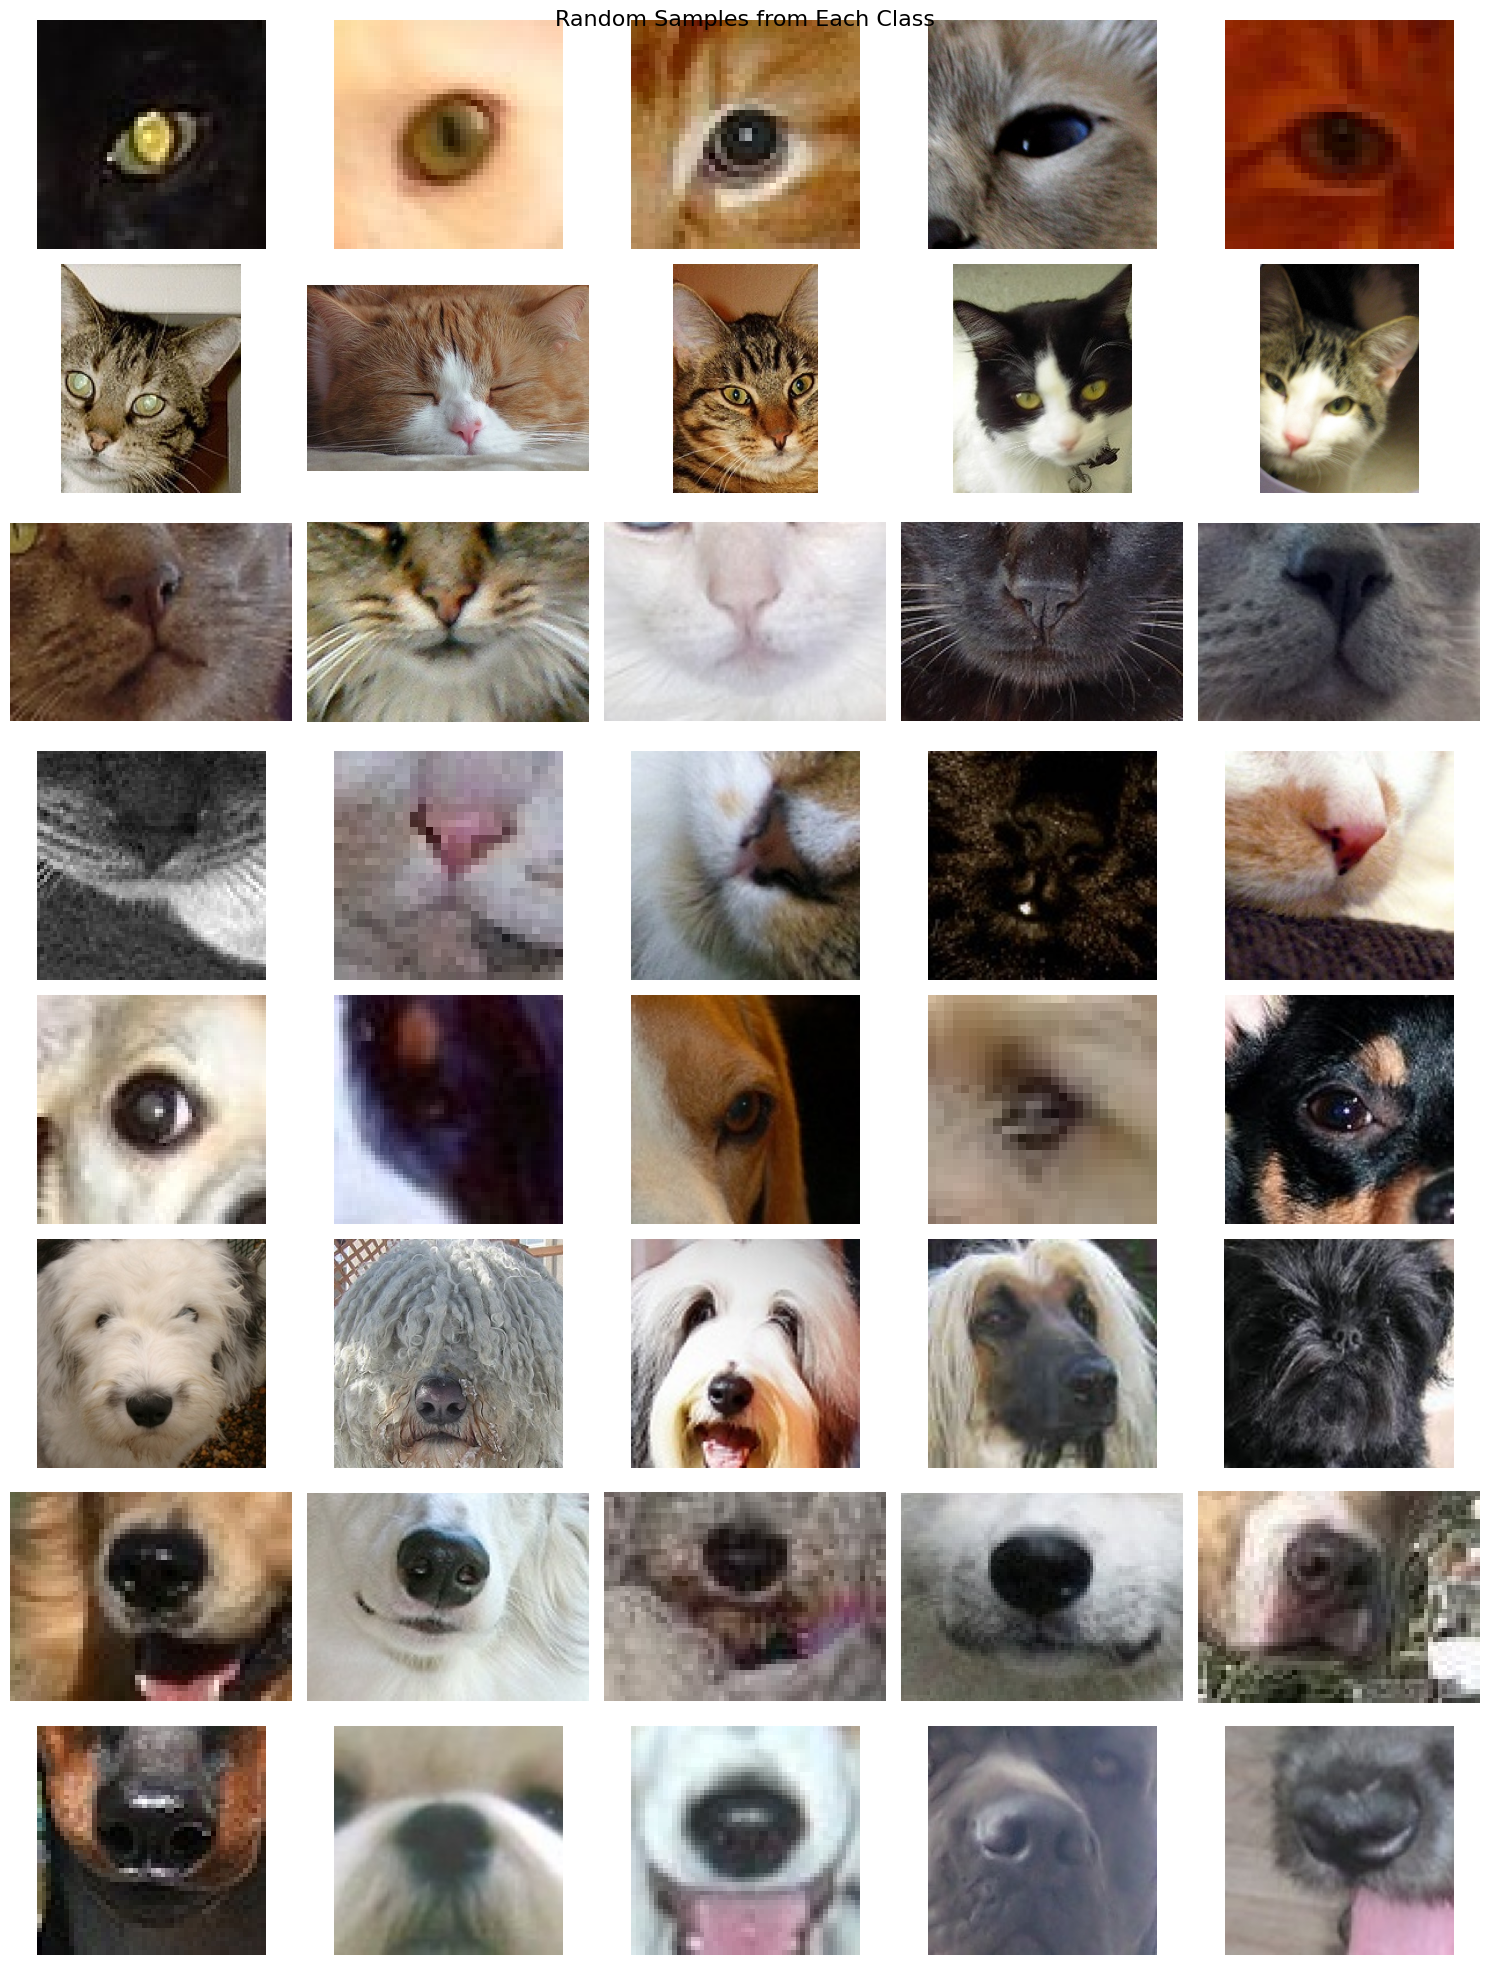

In [14]:
# Randomly select 5 images from each class
fig, axes = plt.subplots(8, 5, figsize=(15, 20))

classes = sorted(train_df["class"].unique())

for row, class_name in enumerate(classes):

    # Select 5 random images from this class
    samples = train_df[
        train_df["class"] == class_name
    ].sample(n=5, random_state=42)

    for col, (_, sample) in enumerate(samples.iterrows()):

        image_id = str(sample["image_id"]).zfill(5)
        image_path = image_lookup[image_id]

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_ylabel(
                class_name,
                fontsize=12,
                rotation=90
            )

plt.suptitle("Random Samples from Each Class", fontsize=16)
plt.tight_layout()
plt.show()

In [15]:
from PIL import Image, UnidentifiedImageError

# Create an empty list to store images that cannot be read
corrupted_images = []

# Go through every training image
for image_path in image_files:

    try:
        # Open the image and check whether its file structure is valid
        with Image.open(image_path) as img:
            img.verify()

        # Reopen the image and check whether its pixels can be loaded
        with Image.open(image_path) as img:
            img.load()

    # If an image causes one of these errors, record the problem
    except (OSError, ValueError, UnidentifiedImageError) as error:
        corrupted_images.append((str(image_path), str(error)))

# Display the total number of images checked
print("Total image files:", len(image_files))

# Display how many images could not be read
print("Corrupted or unreadable images:", len(corrupted_images))

# Show details of the first 10 problematic images, if any
for path, error in corrupted_images[:10]:
    print(path, ":", error)

Total image files: 63660
Corrupted or unreadable images: 0
